In [ ]:
# 1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv(r'C:\Users\MF\Downloads\archive (1)\Ecommerce _Customer_Data.csv', encoding='ISO-8859-1')

print("Dataset Shape:", df.shape)
display(df.head())
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (541909, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Unnamed: 8
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,29-Nov-16,2.55,17850.0,United Kingdom,NaN
1,536365,71053,WHITE METAL LANTERN,6,29-Nov-16,3.39,17850.0,United Kingdom,NaN
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,29-Nov-16,2.75,17850.0,United Kingdom,NaN
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,29-Nov-16,3.39,17850.0,United Kingdom,NaN
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,29-Nov-16,3.39,17850.0,United Kingdom,NaN



Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Unnamed: 8     541909
dtype: int64


In [5]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# 2
df = df.dropna(subset=['CustomerID'])
if 'Unnamed: 8' in df.columns:
    df = df.drop(columns=['Unnamed: 8'])
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print("Cleaned Dataset Shape:", df.shape)
print("Remaining Missing Values:")
print(df.isnull().sum())

Cleaned Dataset Shape: (406829, 9)
Remaining Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64


C:\Users\MF\AppData\Local\Temp\ipykernel_3408\63088926.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


In [ ]:
# 3

# الخطوة الأساسية: حساب مقاييس RFM للعملاء
# هنا بنقسم العملاء حسب الحداثة، التكرار، والقيمة المالية

snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm_df = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency: عدد الأيام من آخر عملية شراء
    'InvoiceNo': 'nunique',                                   # Frequency: عدد الفواتير الفريدة لكل عميل
    'TotalPrice': 'sum'                                       # Monetary: إجمالي المدفوعات من العميل
})

rfm_df.columns = ['Recency', 'Frequency', 'Monetary']

print("--> RFM Table Created Successfully with Shape:", rfm_df.shape)
display(rfm_df.head(3))

--> RFM Table Created Successfully with Shape: (4372, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,2,0.00
12347.0,3,7,4310.00
12348.0,76,4,1797.24


In [ ]:
# 4
print("--- Descriptive Statistics for RFM ---")
display(rfm_df.describe().round(2))

--- Descriptive Statistics for RFM ---


,Recency,Frequency,Monetary
count,4372.00,4372.00,4372.00
mean,92.58,5.08,1898.46
std,100.77,9.34,8219.35
min,1.00,1.00,-4287.63
25%,17.00,1.00,293.36
50%,51.00,3.00,648.08
75%,144.00,5.00,1611.72
max,374.00,248.00,279489.02


In [ ]:
# 5

#ملاحظه وجود ارقام سالبه في جزء ال min  
#  للاحتفاظ بالعملاء اللي ليهم تعاملات إيجابية فقط نقوم بتصفيه جدول ال RFM 
rfm_df = rfm_df[rfm_df['Monetary'] > 0]

print("--> Filtered RFM Shape:", rfm_df.shape)

# استعراض الإحصائيات الوصفية مرة أخرى للتأكد من نظافة الأرقام
display(rfm_df.describe().round(2))

--> Filtered RFM Shape: (4322, 3)


,Recency,Frequency,Monetary
count,4322.00,4322.00,4322.00
mean,90.88,5.12,1923.48
std,99.14,9.38,8263.13
min,1.00,1.00,0.00
25%,17.00,1.00,302.29
50%,50.00,3.00,657.55
75%,139.00,6.00,1625.74
max,374.00,248.00,279489.02


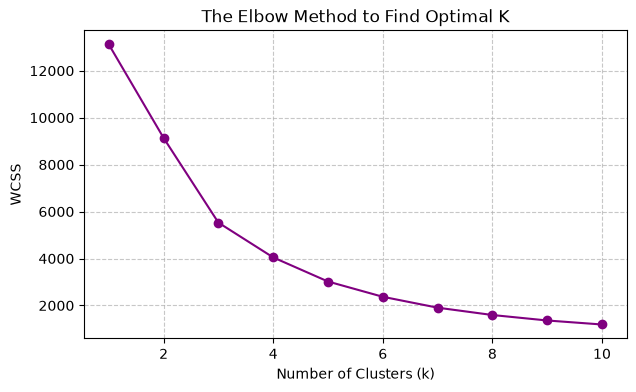

In [17]:
# 6
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_df)

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-', color='purple', linewidth=1.5, markersize=6)
plt.title('The Elbow Method to Find Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

--> Clustering process completed successfully!
Customers distribution per cluster:
Cluster
0    3169
1    1087
3     110
2       6
Name: count, dtype: int64


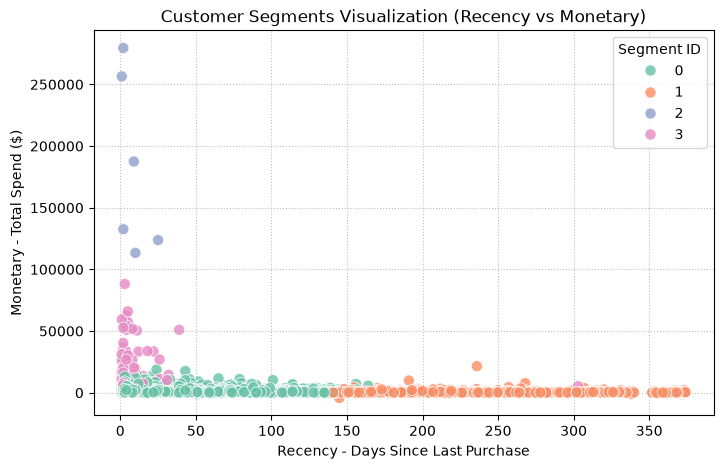

In [19]:
#  7
n_groups = 4

model_clustering = KMeans(n_clusters=n_groups, random_state=42, n_init=10)
rfm_df['Cluster'] = model_clustering.fit_predict(rfm_scaled)

print("--> Clustering process completed successfully!")
print("Customers distribution per cluster:")
print(rfm_df['Cluster'].value_counts())

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=rfm_df, 
    x='Recency', 
    y='Monetary', 
    hue='Cluster', 
    palette='Set2', 
    s=65, 
    alpha=0.8
)

plt.title('Customer Segments Visualization (Recency vs Monetary)')
plt.xlabel('Recency - Days Since Last Purchase')
plt.ylabel('Monetary - Total Spend ($)')
plt.legend(title='Segment ID', loc='upper right')
plt.grid(True, linestyle=':', alpha=0.8)
plt.show()

In [20]:
# 8
cluster_profile = rfm_df.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)
cluster_profile['Customer_Count'] = rfm_df['Cluster'].value_counts()

print("--- Cluster Profiles Summary ---")
display(cluster_profile)

--- Cluster Profiles Summary ---


,Recency,Frequency,Monetary,Customer_Count
Cluster,,,,
0,42.14,4.80,1478.78,3169
1,248.48,1.80,452.72,1087
2,8.17,89.00,182181.98,6
3,9.61,40.67,18441.96,110


C:\Users\MF\AppData\Local\Temp\ipykernel_3408\4007251952.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm_df, x='Cluster', palette='cubehelix')


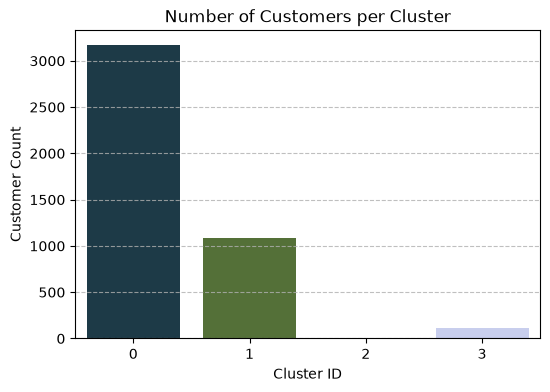

In [23]:
# 9

plt.figure(figsize=(6, 4))
sns.countplot(data=rfm_df, x='Cluster', palette='cubehelix')
plt.title('Number of Customers per Cluster')
plt.xlabel('Cluster ID')
plt.ylabel('Customer Count')
plt.grid(True, axis='y', linestyle='--', alpha=0.8)
plt.show()

## Insights & Marketing Recommendations

Looking at the K-Means clustering results and the average RFM values for each group, we can divide the customers into 4 main segments and apply a different marketing strategy for each:

### 1. VIP / Top Spenders
* **Who they are:** A very small group of customers, but they generate the highest revenue and buy very frequently.
* **Action plan:** Give them special treatment like early access to new products, exclusive discounts, or a VIP loyalty program so we don't lose them to competitors.

### 2. Regular & Loyal Customers
* **Who they are:** Customers who buy consistently with good average spending. They form the main active base of the store.
* **Action plan:** Encourage them to buy a bit more each time by recommending related products (cross-selling) or offering a points-based rewards system.

### 3. At-Risk / Inactive Customers
* **Who they are:** Customers who used to buy before, but a long time has passed since their last order (high Recency).
* **Action plan:** Run win-back email campaigns with time-limited discount codes or special offers to remind them of the store and bring them back.

### 4. Occasional / Low-Value Shoppers
* **Who they are:** Customers with low purchase frequency and small total spend.
* **Action plan:** Keep marketing costs low for this group by using automated emails, seasonal sale notifications, or small bundle deals to encourage a repeat purchase.